<a href="https://colab.research.google.com/github/bandapraneeth/Quantum-Hackathon/blob/main/question_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pennylane scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 50.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 39.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 74.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 76.9 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [23]:
import pandas as pd
from google.colab import files

iris_df = pd.DataFrame(
    X_iris,
    columns=iris.feature_names
)

iris_df["target"] = y_iris

iris_df.to_csv("Iris_D01.csv", index=False)

files.download("Iris_D01.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
wine_df = pd.DataFrame(
    X_wine,
    columns=wine.feature_names
)

wine_df["target"] = y_wine

wine_df.to_csv("Wine_D02.csv", index=False)

files.download("Wine_D02.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import pennylane as qml
from pennylane import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_iris, load_wine

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

print("All libraries imported successfully!")
print("PennyLane version:", qml.__version__)

All libraries imported successfully!
PennyLane version: 0.45.1


In [3]:
iris = load_iris()

X_iris = iris.data[iris.target < 2]
y_iris = iris.target[iris.target < 2]

print("IRIS DATASET")
print("Features:", X_iris.shape)
print("Labels:", y_iris.shape)
print("Classes:", np.unique(y_iris))

IRIS DATASET
Features: (100, 4)
Labels: (100,)
Classes: [0 1]


In [4]:
wine = load_wine()

X_wine = wine.data[wine.target < 2]
y_wine = wine.target[wine.target < 2]

print("WINE DATASET")
print("Features:", X_wine.shape)
print("Labels:", y_wine.shape)
print("Classes:", np.unique(y_wine))

WINE DATASET
Features: (130, 13)
Labels: (130,)
Classes: [0 1]


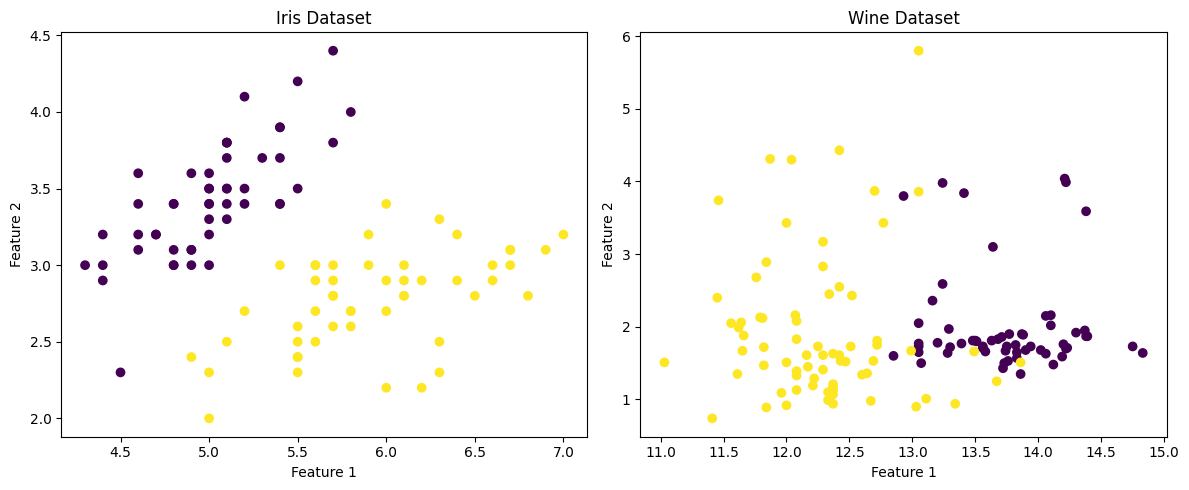

In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(
    X_iris[:, 0],
    X_iris[:, 1],
    c=y_iris
)
plt.title("Iris Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1, 2, 2)
plt.scatter(
    X_wine[:, 0],
    X_wine[:, 1],
    c=y_wine
)
plt.title("Wine Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [6]:
def preprocess(X, y):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        random_state=42,
        stratify=y
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    return X_train, X_test, y_train, y_test


iris_data = preprocess(X_iris, y_iris)

wine_data = preprocess(X_wine, y_wine)

print("Iris training shape:", iris_data[0].shape)
print("Iris testing shape:", iris_data[1].shape)

print("Wine training shape:", wine_data[0].shape)
print("Wine testing shape:", wine_data[1].shape)

Iris training shape: (70, 4)
Iris testing shape: (30, 4)
Wine training shape: (91, 13)
Wine testing shape: (39, 13)


In [7]:
from scipy.linalg import expm

def build_hhl_circuit(A, b, ridge=50, n_phase=7):

    dimension = len(A)

    n_system = int(np.ceil(np.log2(dimension)))
    padded_dim = 2 ** n_system

    A_padded = np.zeros((padded_dim, padded_dim))
    A_padded[:dimension, :dimension] = A

    b_padded = np.zeros(padded_dim)
    b_padded[:dimension] = b

    b_norm = np.linalg.norm(b_padded)

    if b_norm < 1e-12:
        raise ValueError("Right-hand side vector is zero.")

    b_state = b_padded / b_norm

    # Normalize the matrix for Hamiltonian simulation
    scale = np.linalg.norm(A_padded, ord="fro")

    H = A_padded / scale

    # Construct unitary evolution
    U = expm(2j * np.pi * H)

    system_wires = list(range(n_system))

    phase_wires = list(
        range(n_system, n_system + n_phase)
    )

    ancilla = n_system + n_phase

    total_qubits = n_system + n_phase + 1

    dev_hhl = qml.device(
        "default.qubit",
        wires=total_qubits
    )

    powers = [
        np.linalg.matrix_power(
            U,
            2 ** (n_phase - 1 - j)
        )
        for j in range(n_phase)
    ]

    C = 0.5 * ridge / scale

    @qml.qnode(dev_hhl)
    def hhl_circuit():

        # 1. Input state preparation
        qml.StatePrep(
            b_state,
            wires=system_wires
        )

        # 2. Quantum Phase Estimation
        for wire in phase_wires:
            qml.Hadamard(wires=wire)

        for j, wire in enumerate(phase_wires):

            qml.ctrl(
                qml.QubitUnitary,
                control=wire
            )(
                powers[j],
                wires=system_wires
            )

        qml.adjoint(qml.QFT)(
            wires=phase_wires
        )

        # 3. Eigenvalue inversion
        for k in range(1, 2 ** n_phase):

            eigenvalue = k / (2 ** n_phase)

            ratio = min(1.0, C / eigenvalue)

            theta = 2 * np.arcsin(ratio)

            bits = tuple(
                int(x)
                for x in format(k, f"0{n_phase}b")
            )

            qml.ctrl(
                qml.RY,
                control=phase_wires,
                control_values=bits
            )(
                theta,
                wires=ancilla
            )

        # 4. Inverse Quantum Phase Estimation
        qml.QFT(wires=phase_wires)

        for j in reversed(range(n_phase)):

            qml.ctrl(
                qml.QubitUnitary,
                control=phase_wires[j]
            )(
                powers[j].conj().T,
                wires=system_wires
            )

        for wire in phase_wires:
            qml.Hadamard(wires=wire)

        return qml.state()

    return (
        hhl_circuit,
        n_system,
        n_phase,
        total_qubits,
        scale,
        padded_dim
    )

print("HHL quantum circuit function created successfully!")

HHL quantum circuit function created successfully!


In [8]:
def create_linear_system(X, y, ridge=50):

    y_signed = np.where(y == 1, 1.0, -1.0)

    X_augmented = np.column_stack([
        X,
        np.ones(len(X))
    ])

    A = (
        X_augmented.T @ X_augmented
        + ridge * np.eye(X_augmented.shape[1])
    )

    b = X_augmented.T @ y_signed

    return A, b, X_augmented, y_signed


A_iris, b_iris, Z_iris, target_iris = create_linear_system(
    iris_data[0],
    iris_data[2]
)

A_wine, b_wine, Z_wine, target_wine = create_linear_system(
    wine_data[0],
    wine_data[2]
)

print("IRIS SYSTEM")
print("Matrix shape:", A_iris.shape)
print("Vector shape:", b_iris.shape)

print("\nWINE SYSTEM")
print("Matrix shape:", A_wine.shape)
print("Vector shape:", b_wine.shape)

IRIS SYSTEM
Matrix shape: (5, 5)
Vector shape: (5,)

WINE SYSTEM
Matrix shape: (14, 14)
Vector shape: (14,)


In [9]:
print("Running HHL for Iris Dataset...")
start = time.time()
(
    iris_hhl,
    iris_system_qubits,
    iris_phase_qubits,
    iris_total_qubits,
    iris_scale,
    iris_padded_dim
) = build_hhl_circuit(
    A_iris,
    b_iris
)
iris_state = iris_hhl()
iris_hhl_time = time.time() - start
print("\nIris HHL completed!")
print("System Qubits:", iris_system_qubits)
print("Phase Qubits:", iris_phase_qubits)
print("Total Qubits:", iris_total_qubits)
print("Padded Dimension:", iris_padded_dim)
print("Execution Time:", iris_hhl_time)

Running HHL for Iris Dataset...

Iris HHL completed!
System Qubits: 3
Phase Qubits: 7
Total Qubits: 11
Padded Dimension: 8
Execution Time: 0.5636801719665527


In [10]:
print("Running HHL for Wine Dataset...")
start = time.time()
(
    wine_hhl,
    wine_system_qubits,
    wine_phase_qubits,
    wine_total_qubits,
    wine_scale,
    wine_padded_dim
) = build_hhl_circuit(
    A_wine,
    b_wine
)
wine_state = wine_hhl()
wine_hhl_time = time.time() - start
print("\nWine HHL completed!")
print("System Qubits:", wine_system_qubits)
print("Phase Qubits:", wine_phase_qubits)
print("Total Qubits:", wine_total_qubits)
print("Padded Dimension:", wine_padded_dim)
print("Execution Time:", wine_hhl_time)

Running HHL for Wine Dataset...

Wine HHL completed!
System Qubits: 4
Phase Qubits: 7
Total Qubits: 12
Padded Dimension: 16
Execution Time: 0.6464316844940186


In [16]:
def extract_hhl_solution(
    state,
    n_system,
    n_phase,
    original_dimension
):

    tensor = np.asarray(state).reshape(
        [2] * (n_system + n_phase + 1)
    )

    selection = (
        (slice(None),) * n_system
        + (0,) * n_phase
        + (1,)
    )

    # Extract and flatten quantum amplitudes
    amplitudes = tensor[selection].reshape(-1)

    success_probability = np.sum(
        np.abs(amplitudes) ** 2
    )

    if success_probability < 1e-12:
        raise ValueError("HHL success probability is too small.")

    solution = amplitudes / np.sqrt(success_probability)

    return solution[:original_dimension], success_probability


iris_solution, iris_success = extract_hhl_solution(
    iris_state,
    iris_system_qubits,
    iris_phase_qubits,
    A_iris.shape[0]
)

wine_solution, wine_success = extract_hhl_solution(
    wine_state,
    wine_system_qubits,
    wine_phase_qubits,
    A_wine.shape[0]
)

print("Iris Solution Shape:", iris_solution.shape)
print("Iris Success Probability:", iris_success)

print("\nWine Solution Shape:", wine_solution.shape)
print("Wine Success Probability:", wine_success)

Iris Solution Shape: (5,)
Iris Success Probability: 0.009096049215112713

Wine Solution Shape: (14,)
Wine Success Probability: 0.004266825084973358


In [17]:
iris_predictions, iris_scores = quantum_svm_predict(
    iris_data[1],
    iris_solution
)

wine_predictions, wine_scores = quantum_svm_predict(
    wine_data[1],
    wine_solution
)

print("Iris predictions:", iris_predictions[:10])
print("Wine predictions:", wine_predictions[:10])

Iris predictions: [0 0 1 0 0 1 1 1 1 0]
Wine predictions: [1 1 1 1 1 0 0 0 0 0]


In [18]:
def evaluate_classifier(y_true, predictions, scores):
    accuracy = accuracy_score(
        y_true,
        predictions
    )
    balanced = balanced_accuracy_score(
        y_true,
        predictions
    )
    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro"
    )
    cm = confusion_matrix(
        y_true,
        predictions
    )
    auc = roc_auc_score(
        y_true,
        scores
    )
    print("Accuracy:", accuracy)
    print("Balanced Accuracy:", balanced)
    print("Macro-F1:", macro_f1)
    print("AUROC:", auc)
    print("Confusion Matrix:\n", cm)

    return accuracy, balanced, macro_f1, cm, auc


print("IRIS CLASSIFICATION RESULTS")

iris_metrics = evaluate_classifier(
    iris_data[3],
    iris_predictions,
    iris_scores
)

print("\nWINE CLASSIFICATION RESULTS")

wine_metrics = evaluate_classifier(
    wine_data[3],
    wine_predictions,
    wine_scores
)

IRIS CLASSIFICATION RESULTS
Accuracy: 1.0
Balanced Accuracy: 1.0
Macro-F1: 1.0
AUROC: 1.0
Confusion Matrix:
 [[ 0  0  0  0]
 [ 0 15  0  0]
 [ 0  0  0  0]
 [ 0  0  0 15]]

WINE CLASSIFICATION RESULTS
Accuracy: 0.9743589743589743
Balanced Accuracy: 0.9761904761904762
Macro-F1: 0.974291364535267
AUROC: 1.0
Confusion Matrix:
 [[ 0  0  0  0]
 [ 0 18  0  0]
 [ 0  0  0  0]
 [ 0  1  0 20]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [19]:
def calculate_residual(A, b, solution):

    # Restore the approximate solution's scale
    # using the original HHL state normalization.
    classical_reference = np.linalg.solve(A, b)

    reference_state = (
        classical_reference /
        np.linalg.norm(classical_reference)
    )

    fidelity = abs(
        np.vdot(reference_state, solution)
    ) ** 2

    residual = np.linalg.norm(
        A @ solution - b
    ) / np.linalg.norm(b)

    return residual, fidelity


iris_residual, iris_fidelity = calculate_residual(
    A_iris,
    b_iris,
    iris_solution
)

wine_residual, wine_fidelity = calculate_residual(
    A_wine,
    b_wine,
    wine_solution
)

print("IRIS")
print("Linear System Residual:", iris_residual)
print("Solution-State Fidelity:", iris_fidelity)

print("\nWINE")
print("Linear System Residual:", wine_residual)
print("Solution-State Fidelity:", wine_fidelity)

IRIS
Linear System Residual: 1.2079506336476622
Solution-State Fidelity: 0.9999999898851226

WINE
Linear System Residual: 1.2910139992336969
Solution-State Fidelity: 0.9999878531258816


In [20]:
iris_specs = qml.specs(iris_hhl)()
wine_specs = qml.specs(wine_hhl)()

print("IRIS QUANTUM COST")
print("-----------------")

print("Qubits:", iris_total_qubits)
print("Circuit Depth:", iris_specs["resources"].depth)
print("Shots: None (analytic simulation)")
print("Circuit Evaluations: 1")
print("Training Time:", iris_hhl_time)

print("\nWINE QUANTUM COST")
print("-----------------")

print("Qubits:", wine_total_qubits)
print("Circuit Depth:", wine_specs["resources"].depth)
print("Shots: None (analytic simulation)")
print("Circuit Evaluations: 1")
print("Training Time:", wine_hhl_time)

IRIS QUANTUM COST
-----------------
Qubits: 11
Circuit Depth: 145
Shots: None (analytic simulation)
Circuit Evaluations: 1
Training Time: 0.5636801719665527

WINE QUANTUM COST
-----------------
Qubits: 12
Circuit Depth: 145
Shots: None (analytic simulation)
Circuit Evaluations: 1
Training Time: 0.6464316844940186


In [21]:
start = time.time()

iris_predictions, iris_scores = quantum_svm_predict(
    iris_data[1],
    iris_solution
)

iris_inference_time = time.time() - start


start = time.time()

wine_predictions, wine_scores = quantum_svm_predict(
    wine_data[1],
    wine_solution
)

wine_inference_time = time.time() - start


print("Iris Inference Time:", iris_inference_time)
print("Wine Inference Time:", wine_inference_time)

Iris Inference Time: 0.0004341602325439453
Wine Inference Time: 0.00039267539978027344


In [22]:
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro-F1",
        "AUROC",
        "Linear System Residual",
        "Solution-State Fidelity",
        "Success Probability",
        "Qubits",
        "Circuit Depth",
        "Shots",
        "Circuit Evaluations",
        "Training Time",
        "Inference Time"
    ],

    "Iris": [
        iris_metrics[0],
        iris_metrics[1],
        iris_metrics[2],
        iris_metrics[4],
        iris_residual,
        iris_fidelity,
        iris_success,
        iris_total_qubits,
        iris_specs["resources"].depth,
        "Analytic",
        1,
        iris_hhl_time,
        iris_inference_time
    ],

    "Wine": [
        wine_metrics[0],
        wine_metrics[1],
        wine_metrics[2],
        wine_metrics[4],
        wine_residual,
        wine_fidelity,
        wine_success,
        wine_total_qubits,
        wine_specs["resources"].depth,
        "Analytic",
        1,
        wine_hhl_time,
        wine_inference_time
    ]

})

print(comparison.to_string(index=False))

comparison.to_csv(
    "HHL_Quantum_SVM_Results.csv",
    index=False
)

                 Metric                 Iris                 Wine
               Accuracy                  1.0             0.974359
      Balanced Accuracy                  1.0              0.97619
               Macro-F1                  1.0             0.974291
                  AUROC                  1.0                  1.0
 Linear System Residual             1.207951             1.291014
Solution-State Fidelity                  1.0             0.999988
    Success Probability 0.009096049215112713 0.004266825084973358
                 Qubits                   11                   12
          Circuit Depth                  145                  145
                  Shots             Analytic             Analytic
    Circuit Evaluations                    1                    1
          Training Time              0.56368             0.646432
         Inference Time             0.000434             0.000393
